# Блок 8. Глубокое обучение и архитектура нейросетей
## Занятие 4. Ошибка модели и функции потерь: MAE, MSE, RMSE, BCE, Cross-Entropy

## Цель занятия

На занятиях 1–3 мы изучили:

- искусственный нейрон;
- многослойную сеть;
- Forward Pass;
- функции активации.

Сегодня изучаем следующий важный вопрос:

```text
как понять, насколько модель ошибается?
```

Для этого используются **функции потерь**.

---

## Что такое ошибка модели

Модель делает прогноз:

```text
y_pred
```

У нас есть правильный ответ:

```text
y_true
```

Ошибка показывает, насколько прогноз отличается от правильного ответа.

Пример:

```text
Правильный ответ: 80
Прогноз модели: 75
Ошибка: 5
```

---

## Что такое функция потерь

Функция потерь — это формула, которая превращает ошибки модели в одно число.

Это число показывает, насколько плохо работает модель.

Главная идея:

```text
чем меньше loss, тем лучше модель
```

---

## Зачем loss нужен нейросети

Нейросеть обучается так:

1. Делает прогноз.
2. Считает loss.
3. Понимает, насколько ошиблась.
4. Меняет веса.
5. Снова делает прогноз.
6. Снова считает loss.

Так постепенно модель становится лучше.

---

## Основные функции потерь занятия

| Задача | Функция потерь | Где используется |
|---|---|---|
| Регрессия | MAE | средняя абсолютная ошибка |
| Регрессия | MSE | средняя квадратичная ошибка |
| Регрессия | RMSE | корень из MSE |
| Бинарная классификация | Binary Cross-Entropy | выход Sigmoid |
| Многоклассовая классификация | Cross-Entropy | выход Softmax |

---

## MAE

Mean Absolute Error:

```text
MAE = mean(abs(y_true - y_pred))
```

MAE показывает среднюю ошибку в исходных единицах.

---

## MSE

Mean Squared Error:

```text
MSE = mean((y_true - y_pred)^2)
```

MSE сильнее штрафует большие ошибки.

---

## RMSE

Root Mean Squared Error:

```text
RMSE = sqrt(MSE)
```

RMSE возвращает ошибку в исходный масштаб данных.

---

## Binary Cross-Entropy

Используется для бинарной классификации.

```text
BCE = -mean(y*log(p) + (1-y)*log(1-p))
```

Где:

- `y` — правильный класс 0 или 1;
- `p` — вероятность класса 1.

---

## Cross-Entropy

Используется для многоклассовой классификации.

Если правильный класс имеет низкую вероятность, loss будет большим.

---

## Связь с будущими занятиями

Функции потерь нужны для:

- градиентного спуска;
- backpropagation;
- обучения PyTorch-моделей;
- CNN;
- RNN;
- LSTM;
- Transformer.

---

## Связь с дипломом

В дипломном проекте студент должен уметь объяснить:

- какая задача решается: регрессия или классификация;
- какая функция потерь выбрана;
- почему именно она;
- что означает значение loss;
- как loss связан с качеством модели.

---

## GitHub Workflow занятия

```bash
git checkout main
git pull origin main
git checkout -b feature/block8-lesson04-loss-functions

git add .
git commit -m "feat: add block8 lesson04 loss functions"
git push -u origin feature/block8-lesson04-loss-functions
```

---

## Задача урока для переноса в VS Code

Создать файл:

```text
src/losses.py
```

Реализовать функции:

```python
mae(y_true, y_pred)
mse(y_true, y_pred)
rmse(y_true, y_pred)
binary_cross_entropy(y_true, y_prob)
cross_entropy(y_true_labels, y_prob_matrix)
```

Добавить `assert`-проверки и небольшой запуск в `main.py`.


Сначала изучите SOLVED-ноутбук вместе с преподавателем. Затем выполните TODO-версию самостоятельно.

## Ячейка 1. TODO: импорт библиотек

### Алгоритм

1. Импортируйте `numpy`.
2. Импортируйте `pandas`.
3. Импортируйте `matplotlib.pyplot`.
4. Настройте `np.random.seed(42)`.
5. Проверьте импорты через `assert`.

In [23]:
# TODO: импортируйте numpy как np
import numpy as np
# TODO: импортируйте pandas как pd
import pandas as pd
# TODO: импортируйте matplotlib.pyplot как plt
import matplotlib.pyplot as plt

# TODO: настройте np.random.seed(42)
np.random.seed(42)
# TODO: выведите сообщение "Библиотеки подключены"
print("Библиотеки подключены")
print("NumPy version:", np.__version__)

# TODO: добавьте assert-проверки
assert np is not None
assert pd is not None
assert plt is not None

Библиотеки подключены
NumPy version: 2.5.4


## Ячейка 2. TODO: мини-задача регрессии

### Алгоритм

1. Создайте `y_true_reg`.
2. Создайте прогнозы `pred_good`, `pred_medium`, `pred_bad`.
3. Соберите таблицу `regression_table`.
4. Постройте график факта и прогнозов.
5. Проверьте размеры массивов.

,y_true,pred_good,pred_medium,pred_bad
0,50.000000,50.821868,53.097053,47.737469
1,52.631579,52.448214,50.885891,64.607994
2,55.263158,56.338952,60.911534,62.472702
3,57.894737,58.486841,62.612190,51.139936
4,60.526316,59.308848,63.866918,72.487669
5,63.157895,64.584762,59.493559,74.129412
6,65.789474,66.572893,65.390126,61.738695
7,68.421053,69.279246,62.946698,60.800864
8,71.052632,69.936972,66.904105,77.622470
9,73.684211,73.535368,75.880798,60.715300


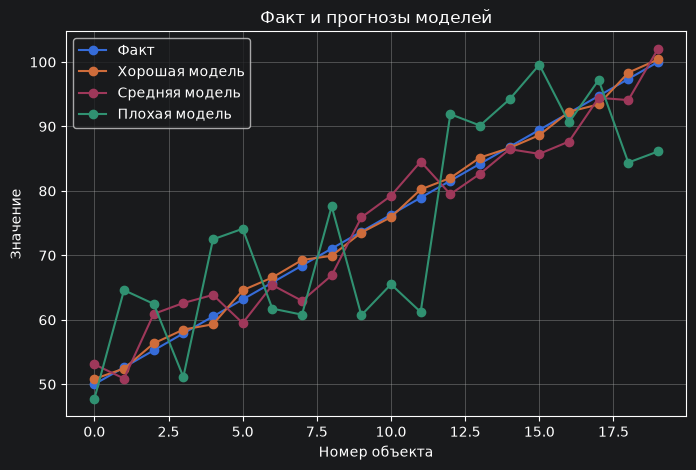

In [24]:
# TODO: создайте y_true_reg
n = 20
rng = np.random.default_rng(seed=42)
y_true_reg = np.linspace(start=50, stop=100, num=n)
# TODO: создайте pred_good
noise_good = rng.uniform(low=-1.5, high=1.5, size=y_true_reg.shape)
pred_good = y_true_reg + noise_good
# TODO: создайте pred_medium
noise_medium = rng.uniform(low=-6, high=6, size=y_true_reg.shape)
pred_medium = y_true_reg + noise_medium
# TODO: создайте pred_bad
noise_bad = rng.uniform(low=-18, high=18, size=y_true_reg.shape)
pred_bad = y_true_reg + noise_bad
# TODO: создайте regression_table
regression_table = pd.DataFrame({
    "y_true": y_true_reg,
    "pred_good": pred_good,
    "pred_medium": pred_medium,
    "pred_bad": pred_bad
})
# TODO: покажите таблицу через display
display(regression_table)
# TODO: постройте график факта и прогнозов
plt.figure(figsize=(8, 5))
plt.plot(y_true_reg, marker="o", label="Факт")
plt.plot(pred_good, marker="o", label="Хорошая модель")
plt.plot(pred_medium, marker="o", label="Средняя модель")
plt.plot(pred_bad, marker="o", label="Плохая модель")
plt.title("Факт и прогнозы моделей")
plt.xlabel("Номер объекта")
plt.ylabel("Значение")
plt.grid(True)
plt.legend()
plt.show()
# TODO: assert len(y_true_reg) == len(pred_good)
assert len(y_true_reg) == len(pred_good) == len(pred_medium) == len(pred_bad)
assert regression_table.shape == (20, 4)

## Ячейка 3. TODO: MAE

### Алгоритм

1. Создайте функцию `mae(y_true, y_pred)`.
2. Посчитайте MAE для трёх моделей.
3. Выведите результаты.
4. Проверьте функцию через `assert`.

In [25]:
# TODO: создайте функцию mae(y_true, y_pred)
def mae(y_true, y_pred):
    errors = np.abs(y_true - y_pred)
    return np.mean(errors)


# TODO: посчитайте mae_good
mae_good = mae(y_true_reg, pred_good)
# TODO: посчитайте mae_medium
mae_medium = mae(y_true_reg, pred_medium)
# TODO: посчитайте mae_bad
mae_bad = mae(y_true_reg, pred_bad)
# TODO: выведите значения MAE
print("MAE хорошей модели:", mae_good)
print("MAE средней модели:", mae_medium)
print("MAE плохой модели:", mae_bad)
# TODO: assert mae_good < mae_medium < mae_bad
assert mae_good < mae_medium < mae_bad

MAE хорошей модели: 0.7564795316402517
MAE средней модели: 3.038158959860506
MAE плохой модели: 8.771909317866445


## Ячейка 4. TODO: MSE и RMSE

### Алгоритм

1. Создайте функцию `mse`.
2. Создайте функцию `rmse`.
3. Создайте таблицу `loss_report_reg`.
4. Проверьте размер таблицы.

In [26]:
# TODO: создайте функцию mse(y_true, y_pred)
def mse(y_true, y_pred):
    errors = y_true - y_pred
    return np.mean(errors ** 2)


# TODO: создайте функцию rmse(y_true, y_pred)
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


# TODO: создайте loss_report_reg
loss_report_reg = pd.DataFrame({
    "model": ["good", "medium", "bad"],
    "MAE": [
        mae(y_true_reg, pred_good),
        mae(y_true_reg, pred_medium),
        mae(y_true_reg, pred_bad)
    ],
    "MSE": [
        mse(y_true_reg, pred_good),
        mse(y_true_reg, pred_medium),
        mse(y_true_reg, pred_bad)
    ],
    "RMSE": [
        rmse(y_true_reg, pred_good),
        rmse(y_true_reg, pred_medium),
        rmse(y_true_reg, pred_bad)
    ]
})
# TODO: покажите loss_report_reg
display(loss_report_reg)
# TODO: assert loss_report_reg.shape == (3, 4)
assert mse(np.array([10, 20]), np.array([12, 18])) == 4
assert rmse(np.array([10, 20]), np.array([12, 18])) == 2
assert loss_report_reg.shape == (3, 4)

,model,MAE,MSE,RMSE
0,good,0.756480,0.741257,0.860963
1,medium,3.038159,11.957549,3.457969
2,bad,8.771909,94.715601,9.732194


## Ячейка 5. TODO: визуальное сравнение функций потерь регрессии

### Алгоритм

1. Создайте позиции для столбцов.
2. Постройте столбчатый график MAE и RMSE.
3. Найдите лучшую модель по RMSE.
4. Проверьте результат через `assert`.

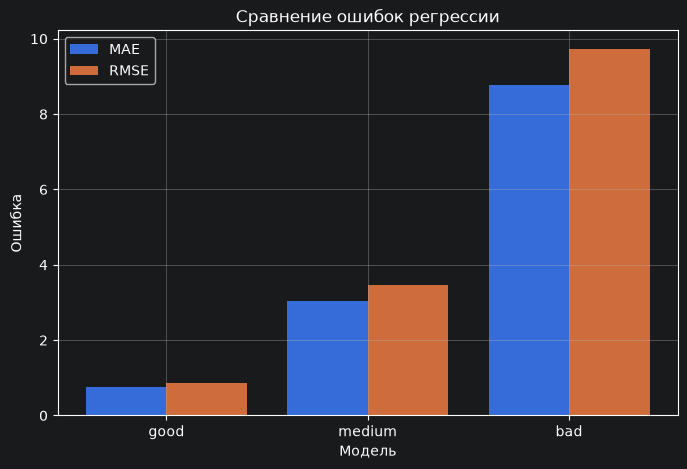

Лучшая модель по RMSE: good


In [27]:
# TODO: создайте x_positions
x_positions = np.arange(len(loss_report_reg))
# TODO: постройте bar-график MAE и RMSE
plt.figure(figsize=(8, 5))
plt.bar(x_positions - 0.2, loss_report_reg["MAE"], width=0.4, label="MAE")
plt.bar(x_positions + 0.2, loss_report_reg["RMSE"], width=0.4, label="RMSE")
plt.xticks(x_positions, loss_report_reg["model"])
plt.title("Сравнение ошибок регрессии")
plt.xlabel("Модель")
plt.ylabel("Ошибка")
plt.grid(True)
plt.legend()
plt.show()
# TODO: добавьте xticks, title, xlabel, ylabel, grid, legend
best_regression_model = loss_report_reg.sort_values("RMSE").iloc[0]["model"]
# TODO: найдите best_regression_model
print("Лучшая модель по RMSE:", best_regression_model)

# TODO: assert best_regression_model == "good"
assert best_regression_model == "good"
assert loss_report_reg["RMSE"].min() == loss_report_reg.loc[0, "RMSE"]

## Ячейка 6. TODO: Binary Cross-Entropy

### Алгоритм

1. Создайте правильные ответы `y_true_class`.
2. Создайте вероятности `prob_good` и `prob_bad`.
3. Создайте функцию `binary_cross_entropy`.
4. Посчитайте BCE.
5. Проверьте, что хорошая модель имеет меньший loss.

In [28]:
# TODO: создайте y_true_class
y_true_class = rng.integers(0, 2, size=n).astype(float)
# TODO: создайте prob_good
prob_good = np.where(
    y_true_class == 1,
    rng.uniform(0.75, 0.99, size=n),
    rng.uniform(0.01, 0.25, size=n),
)
prob_good = np.round(prob_good, 2)
# TODO: создайте prob_bad
prob_bad = rng.uniform(0.45, 0.55, size=n)
prob_bad = np.round(prob_bad, 2)


# TODO: создайте функцию binary_cross_entropy(y_true, y_prob)
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-12
    y_prob = np.clip(y_prob, eps, 1 - eps)
    loss = -(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))
    return np.mean(loss)


# TODO: посчитайте bce_good
bce_good = binary_cross_entropy(y_true_class, prob_good)

# TODO: посчитайте bce_bad
bce_bad = binary_cross_entropy(y_true_class, prob_bad)

print("BCE хорошей модели:", round(float(bce_good), 4))
print("BCE слабой модели:", round(float(bce_bad), 4))
# TODO: assert bce_good < bce_bad
assert bce_good < bce_bad
assert binary_cross_entropy(np.array([1]), np.array([0.9])) < binary_cross_entropy(np.array([1]), np.array([0.1]))

BCE хорошей модели: 0.1365
BCE слабой модели: 0.6955


## Ячейка 7. TODO: график Binary Cross-Entropy

### Алгоритм

1. Создайте массив probabilities от 0.001 до 0.999.
2. Посчитайте loss для y=1.
3. Посчитайте loss для y=0.
4. Постройте графики.
5. Проверьте направление изменения loss.

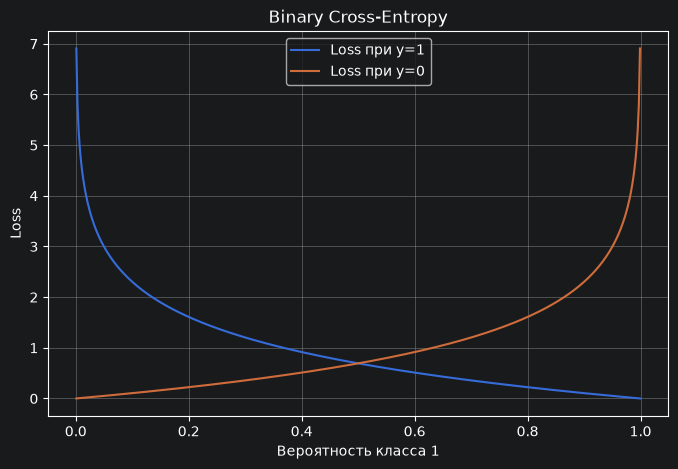

In [33]:
# TODO: создайте probabilities
probabilities = np.linspace(0.001, 0.999, 500)
# TODO: посчитайте loss_when_y_is_1
loss_when_y_is_1 = -np.log(probabilities)
# TODO: посчитайте loss_when_y_is_0
loss_when_y_is_0 = -np.log(1 - probabilities)

# TODO: постройте два графика
plt.figure(figsize=(8, 5))
plt.plot(probabilities, loss_when_y_is_1, label="Loss при y=1")
plt.plot(probabilities, loss_when_y_is_0, label="Loss при y=0")
plt.title("Binary Cross-Entropy")
plt.xlabel("Вероятность класса 1")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()
# TODO: добавьте title, xlabel, ylabel, grid, legend

# TODO: assert loss_when_y_is_1[0] > loss_when_y_is_1[-1]
assert len(probabilities) == len(loss_when_y_is_1)
assert loss_when_y_is_1[0] > loss_when_y_is_1[-1]
assert loss_when_y_is_0[0] < loss_when_y_is_0[-1]

## Ячейка 8. TODO: почему accuracy недостаточно

### Алгоритм

1. Создайте две модели: уверенную и неуверенную.
2. Получите классы через порог 0.5.
3. Посчитайте accuracy.
4. Посчитайте BCE.
5. Соберите таблицу и сделайте вывод.

In [43]:
# TODO: создайте prob_confident
prob_confident = np.where(
    y_true_class == 1,
    rng.uniform(0.90, 0.99, size=n),
    rng.uniform(0.01, 0.10, size=n),
)
prob_confident = np.round(prob_confident, 2)

# TODO: создайте prob_uncertain
prob_uncertain = np.where(
    y_true_class == 1,
    rng.uniform(0.51, 0.55, size=n),  # чуть выше 0.5 → pred = 1 ✅
    rng.uniform(0.45, 0.49, size=n),  # чуть ниже 0.5 → pred = 0 ✅
)
prob_uncertain = np.round(prob_uncertain, 2)

# TODO: создайте pred_confident
pred_confident = (prob_confident >= 0.5).astype(int)

# TODO: создайте pred_uncertain
pred_uncertain = (prob_uncertain >= 0.5).astype(int)

# TODO: посчитайте accuracy_confident
accuracy_confident = np.mean(pred_confident == y_true_class)
# TODO: посчитайте accuracy_uncertain
accuracy_uncertain = np.mean(pred_uncertain == y_true_class)
# TODO: посчитайте bce_confident и bce_uncertain
bce_confident = binary_cross_entropy(y_true_class, prob_confident)
bce_uncertain = binary_cross_entropy(y_true_class, prob_uncertain)
# TODO: создайте accuracy_vs_loss
accuracy_vs_loss = pd.DataFrame({
    "model": ["confident", "uncertain"],
    "accuracy": [accuracy_confident, accuracy_uncertain],
    "BCE": [bce_confident, bce_uncertain]
})
# TODO: display(accuracy_vs_loss)
display(accuracy_vs_loss)
# TODO: assert accuracy_confident == accuracy_uncertain
assert accuracy_confident == accuracy_uncertain

# TODO: assert bce_confident < bce_uncertain
assert bce_confident < bce_uncertain

,model,accuracy,BCE
0,confident,1.0,0.058930
1,uncertain,1.0,0.634175


## Ячейка 9. TODO: Cross-Entropy для многоклассовой классификации

### Алгоритм

1. Создайте `y_true_labels`.
2. Создайте `prob_matrix_good`.
3. Создайте `prob_matrix_bad`.
4. Создайте функцию `cross_entropy`.
5. Посчитайте CE и сравните модели.

In [45]:
import numpy as np

rng = np.random.default_rng(seed=42)

y_true_labels = np.array([0, 1, 2, 1])
n = len(y_true_labels)
n_classes = 3

prob_matrix_good = np.zeros((n, n_classes))
for i, y in enumerate(y_true_labels):
    alpha = np.ones(n_classes)
    alpha[y] = 20
    prob_matrix_good[i] = rng.dirichlet(alpha)

prob_matrix_bad = rng.dirichlet(np.ones(n_classes), size=n)


def cross_entropy(y_true_labels, y_prob_matrix):
    eps = 1e-12
    y_prob_matrix = np.clip(y_prob_matrix, eps, 1 - eps)
    true_class_probabilities = y_prob_matrix[np.arange(len(y_true_labels)), y_true_labels]
    return np.mean(-np.log(true_class_probabilities))


ce_good = cross_entropy(y_true_labels, prob_matrix_good)
ce_bad = cross_entropy(y_true_labels, prob_matrix_bad)

print("CE good:", round(float(ce_good), 4))
print("CE bad: ", round(float(ce_bad), 4))
print("sums good:", prob_matrix_good.sum(axis=1))
print("sums bad: ", prob_matrix_bad.sum(axis=1))

assert ce_good < ce_bad
assert np.allclose(prob_matrix_good.sum(axis=1), 1)
assert np.allclose(prob_matrix_bad.sum(axis=1), 1)

CE good: 0.1096
CE bad:  1.3861
sums good: [1. 1. 1. 1.]
sums bad:  [1. 1. 1. 1.]


## Ячейка 10. TODO: loss как поверхность для оптимизации и итоговый отчёт

### Алгоритм

1. Создайте простую задачу `y = 2*x`.
2. Переберите разные веса.
3. Для каждого веса посчитайте MSE.
4. Постройте график loss от веса.
5. Найдите лучший вес.
6. Создайте `lesson_report` и GitHub Workflow.

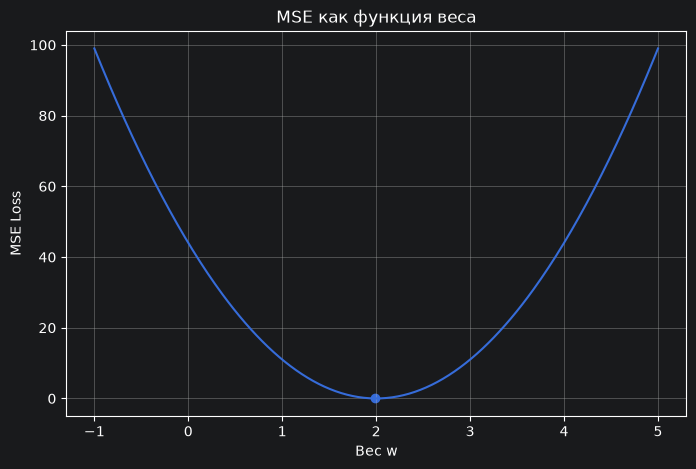

Рекомендации по выбору loss:
- regression : MAE, MSE или RMSE
- binary_classification : Binary Cross-Entropy
- multiclass_classification : Cross-Entropy

Итоговый отчёт занятия:
topic : Функции потерь
regression_losses : ['MAE', 'MSE', 'RMSE']
binary_loss : Binary Cross-Entropy
multiclass_loss : Cross-Entropy
best_w_in_demo : 1.99
vscode_file : src/losses.py

GitHub:
git checkout main
git pull origin main
git checkout -b feature/block8-lesson04-loss-functions
git add .
git commit -m "feat: add block8 lesson04 loss functions"
git push -u origin feature/block8-lesson04-loss-functions


In [46]:
# TODO: создайте x_simple
x_simple = np.array([1, 2, 3, 4, 5], dtype=float)
# TODO: создайте y_simple
y_simple = np.array([2, 4, 6, 8, 10], dtype=float)
# TODO: создайте w_values
w_values = np.linspace(-1, 5, 300)
# TODO: в цикле посчитайте loss_values
loss_values = []
for w_value in w_values:
    y_pred_simple = w_value * x_simple
    loss_values.append(mse(y_simple, y_pred_simple))

loss_values = np.array(loss_values)
# TODO: найдите best_w и best_loss
best_index = np.argmin(loss_values)
best_w = w_values[best_index]
best_loss = loss_values[best_index]
# TODO: постройте график MSE от веса
plt.figure(figsize=(8, 5))
plt.plot(w_values, loss_values)
plt.scatter([best_w], [best_loss])
plt.title("MSE как функция веса")
plt.xlabel("Вес w")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()
# TODO: создайте loss_recommendations
loss_recommendations = {
    "regression": "MAE, MSE или RMSE",
    "binary_classification": "Binary Cross-Entropy",
    "multiclass_classification": "Cross-Entropy"
}
# TODO: создайте lesson_report
lesson_report = {
    "topic": "Функции потерь",
    "regression_losses": ["MAE", "MSE", "RMSE"],
    "binary_loss": "Binary Cross-Entropy",
    "multiclass_loss": "Cross-Entropy",
    "best_w_in_demo": round(float(best_w), 3),
    "vscode_file": "src/losses.py"
}
print("Рекомендации по выбору loss:")
for task, recommendation in loss_recommendations.items():
    print("-", task, ":", recommendation)
print()
print("Итоговый отчёт занятия:")
for key, value in lesson_report.items():
    print(key, ":", value)
# TODO: выведите GitHub Workflow
print()
print("GitHub:")
print("git checkout main")
print("git pull origin main")
print("git checkout -b feature/block8-lesson04-loss-functions")
print("git add .")
print('git commit -m "feat: add block8 lesson04 loss functions"')
print("git push -u origin feature/block8-lesson04-loss-functions")
# TODO: assert abs(best_w - 2) < 0.05
assert abs(best_w - 2) < 0.05
assert "MSE" in lesson_report["regression_losses"]
assert lesson_report["binary_loss"] == "Binary Cross-Entropy"

# Итог TODO-задания

Покажите преподавателю:

- функции `mae`, `mse`, `rmse`;
- функцию `binary_cross_entropy`;
- функцию `cross_entropy`;
- таблицу сравнения регрессионных моделей;
- график Binary Cross-Entropy;
- пример, почему accuracy недостаточно;
- график loss от веса;
- GitHub-коммит;
- файл `src/losses.py` в VS Code.